<center>
  <img src="https://upload.wikimedia.org/wikipedia/commons/6/68/Logo_FPT_Education.png" width="300" alt="FPT Education logo" />
</center>

# 3.2. Phân tích và trực quan hóa bằng Python

**Dữ liệu:** `data/processed/olist_analysis_dataset.csv` - bảng phân tích gồm `order_id`, `delay_days`, `item_count`, `review_score`, `low_review`.

Mục tiêu: dùng biểu đồ kiểm tra mối liên hệ giữa độ trễ giao hàng, số lượng sản phẩm trong đơn với điểm đánh giá của khách hàng, làm cơ sở cho phần Nhận định về lựa chọn đặc trưng.

### Chuẩn bị dữ liệu

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")

In [2]:
BASE_DIR = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "processed").is_dir())
FIGURES_DIR = BASE_DIR / "report" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
df = pd.read_csv(BASE_DIR / "data" / "processed" / "olist_analysis_dataset.csv")

print(df.shape)
df.head()

(95824, 5)


,order_id,delay_days,item_count,review_score,low_review
0,e481f51cbdc54678b7cc49136f2d6af7,-8,1,4,0
1,53cdb2fc8bc7dce0b6741e2150273451,-6,1,4,0
2,47770eb9100c2d0c44946d9cf07ec65d,-18,1,5,0
3,949d5b44dbf5de918fe9c16f97b45f8a,-13,1,5,0
4,ad21c59c0840e6cb83a9ceb5573f8159,-10,1,5,0


In [3]:
print(df.dtypes)
print(df.isnull().sum())

order_id          str
delay_days      int64
item_count      int64
review_score    int64
low_review      int64
dtype: object
order_id        0
delay_days      0
item_count      0
review_score    0
low_review      0
dtype: int64


In [4]:
# Loại dòng thiếu dữ liệu ở các biến dùng để phân tích (dữ liệu hiện tại không có giá trị thiếu)
df = df.dropna(subset=["delay_days", "item_count", "review_score", "low_review"])
print("Số dòng sau khi kiểm tra:", len(df))

Số dòng sau khi kiểm tra: 95824


## 3.2.1. Độ trễ giao hàng và điểm đánh giá

**Câu hỏi nghiên cứu:** Đơn hàng có điểm đánh giá thấp có xu hướng bị giao trễ hơn không?

Biểu đồ box plot so sánh phân phối `delay_days` theo từng mức `review_score` (1-5). Đường đỏ nét đứt là mốc `delay_days = 0` (giao đúng hạn).

              median   mean
review_score               
1               -7.0  -4.04
2              -10.0  -8.66
3              -11.0 -10.77
4              -12.0 -12.38
5              -13.0 -13.38


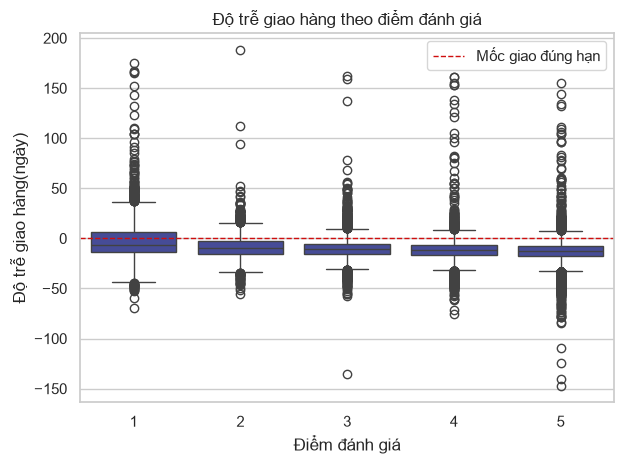

In [5]:
print(df.groupby("review_score")["delay_days"].agg(["median","mean"]).round(2))
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x= "review_score", y="delay_days", color= "#3840a4")
plt.axhline(0, color = "#cf0e0e", linestyle = "--", linewidth =1, label = "On-time delivery (delay = 0)")
plt.title("Delivery Delay by Review Score")
plt.xlabel("Review Score")
plt.ylabel("Delivery Delay (days)")
plt.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "delivery_delay_by_review_score.png", dpi=300, bbox_inches="tight")
plt.show()

**Nhận xét:** Trung vị delay_days tăng đều từ -13 ngày (score 5) lên -7 ngày (score 1); trung bình tăng từ -13,38 lên -4,04 ngày. Gần một nửa tổng mức chênh lệch nằm ở bước chuyển từ score 2 sang score 1, trong khi giữa score 2 đến 5 chênh lệch rất nhỏ. Ở score 1, trung bình cao hơn trung vị khoảng 3 ngày, cho thấy phân phối lệch phải do một số đơn trễ rất nặng. Đáng chú ý, trung vị của cả nhóm score 1 vẫn âm, nghĩa là phần lớn đơn bị đánh giá thấp vẫn được giao sớm hơn dự kiến. Do đó delay_days là tín hiệu có ích nhưng không đủ để giải thích đánh giá thấp, và quan hệ có dạng ngưỡng (trễ hay không trễ) hơn là quan hệ tuyến tính. Điều này gợi ý tạo thêm các biến is_late, late_days, early_days và bổ sung biến ngoài độ trễ giao hàng cho mô hình.

## 3.2.2. Trạng thái giao hàng và tỷ lệ đánh giá thấp

**Câu hỏi nghiên cứu:** Đơn giao trễ có tỷ lệ đánh giá thấp cao hơn đơn giao đúng hạn hoặc đến sớm không?

Chia đơn thành hai nhóm: **Late** (`delay_days > 0`) và **On time / Early** (`delay_days <= 0`), sau đó tính `low_review_rate = mean(low_review) * 100`.

                   count  mean  low_review_rate
delivery_status                                
Giao trễ            6381  0.62            62.37
Đúng hạn hoặc sớm  89443  0.09             9.27


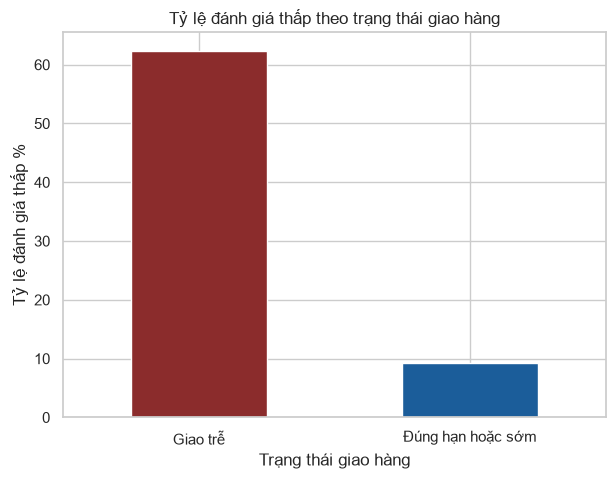

In [6]:
df["delivery_status"] = np.where(df["delay_days"] > 0, "Late", "On time or early")
summary = df.groupby("delivery_status")["low_review"].agg(["count", "mean"])
summary["low_review_rate"] = summary["mean"]*100 
print(summary.round(2))

ax =summary["low_review_rate"].plot(kind="bar", figsize = (7,5), color=("#8b2c2c", "#1b5d9a"))
ax.set_xticklabels(summary.index, rotation = 0)

plt.title("Low Review Rate by Delivery Status")
plt.xlabel("Delivery Status")
plt.ylabel("Low Review Rate (%)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "low_review_rate_by_delivery_status.png", dpi=300, bbox_inches="tight")
plt.show()


**Nhận xét:** đơn giao trễ có tỷ lệ đánh giá thấp 62,37% (3.980/6.381 đơn), cao hơn 53,10 điểm phần trăm so với đơn đúng hạn hoặc sớm (9,27%, tương ứng 8.288/89.443 đơn). Đơn trễ chỉ chiếm 6,66% tổng số đơn nhưng đóng góp 3.980/12.268 đánh giá thấp, tức khoảng 32,4%.


## 3.2.3. Số lượng sản phẩm và tỷ lệ đánh giá thấp

**Câu hỏi nghiên cứu:** Số lượng sản phẩm trong đơn có liên quan đến khả năng nhận đánh giá thấp không?

Gộp `item_count` thành ba nhóm: 1 sản phẩm, 2-3 sản phẩm và từ 4 sản phẩm trở lên.

              count  mean  low_review_rate
item_group                                
1 sản phẩm    86296  0.11            11.25
2-3 sản phẩm   8605  0.26            26.04
4+ sản phẩm     923  0.34            34.24


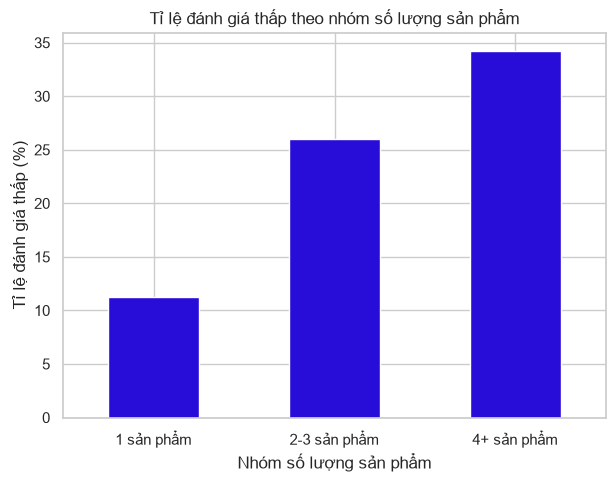

In [9]:
df["item_group"] = np.select(
    [df["item_count"] == 1, df["item_count"].between(2, 3)],
    ["1 item", "2-3 items"],
    default = "4+ items",
)

summary = df.groupby("item_group")["low_review"].agg(["count", "mean"])
summary["low_review_rate"] = summary["mean"]*100
summary = summary.reindex(["1 item", "2-3 items", "4+ items"])
print(summary.round(2))
ax = summary["low_review_rate"].plot(kind="bar", figsize=(7,5), color="#280dd8")
ax.set_xticklabels(summary.index, rotation =0 )

plt.title("Low Review Rate by Number of Items")
plt.xlabel("Number of Items per Order")
plt.ylabel("Low Review Rate (%)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "low_review_rate_by_item_count.png", dpi=300, bbox_inches="tight")
plt.show()


**Nhận xét:** tỷ lệ đánh giá thấp tăng theo số lượng sản phẩm: 11,25% với đơn 1 sản phẩm (86.296 đơn), 26,04% với đơn 2-3 sản phẩm (8.605 đơn) và 34,24% với đơn từ 4 sản phẩm (923 đơn). Chênh lệch giữa nhóm 1 sản phẩm và nhóm 2-3 sản phẩm là 14,79 điểm phần trăm, cho thấy số lượng sản phẩm có liên hệ với xác suất bị đánh giá thấp, dù nhóm 4+ sản phẩm có ít đơn hơn.

## 3.2.4. Bản đồ nhiệt tương quan Spearman

**Câu hỏi nghiên cứu:** Độ trễ giao hàng, số lượng sản phẩm và điểm đánh giá có mức độ liên hệ với nhau như thế nào?

Tính hệ số tương quan Spearman (phù hợp với dữ liệu không phân phối chuẩn và có nhiều giá trị ngoại lệ) giữa `delay_days`, `item_count` và `review_score`.

              delay_days  item_count  review_score
delay_days         1.000      -0.036        -0.176
item_count        -0.036       1.000        -0.108
review_score      -0.176      -0.108         1.000


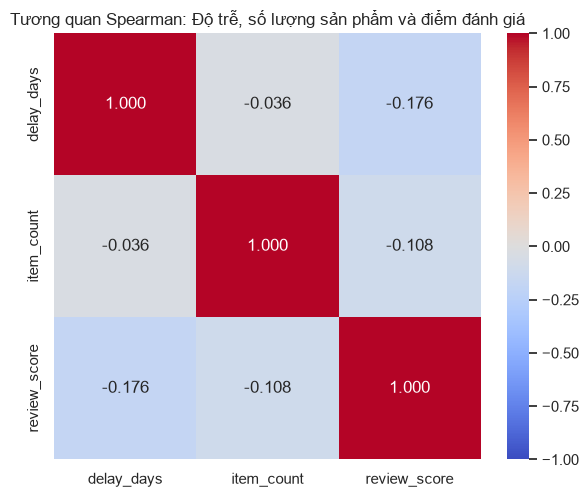

In [8]:
corr = df[["delay_days", "item_count", "review_score"]].corr(method="spearman")
print(corr.round(3))

plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt=".3f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Spearman Correlation: Delivery Delay, Item Count, and Review Score")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "spearman_correlation_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

**Nhận xét:**
- `delay_days` và `review_score`: **-0,176** - tương quan âm yếu, đơn càng trễ thì điểm đánh giá càng có xu hướng thấp.
- `item_count` và `review_score`: **-0,108** - tương quan âm yếu, đơn nhiều sản phẩm có xu hướng bị đánh giá thấp hơn.


Cả hai biến đều tương quan yếu với điểm đánh giá, trong đó độ trễ có mức liên hệ cao hơn số lượng sản phẩm. Tương quan không chứng minh quan hệ nhân quả, và hệ số thấp không đủ để kết luận một biến không có giá trị dự đoán.


# 3.3. Nhận định về lựa chọn đặc trưng

Tổng hợp kết quả của bốn biểu đồ để đưa ra quyết định ban đầu về hai biến đầu vào:

| Đặc trưng | Bằng chứng từ phân tích | Quyết định ban đầu |
|---|---|---|
| `delay_days` | Biểu đồ hộp: trung vị độ trễ tăng từ -7 ngày (điểm 1) lên -13 ngày (điểm 5). Tỷ lệ đánh giá thấp theo trạng thái giao hàng: 62,37% (giao trễ) so với 9,27% (đúng hạn hoặc sớm). Spearman: -0,176 với `review_score`. | Giữ lại |
| `item_count` | Tỷ lệ đánh giá thấp theo nhóm số lượng sản phẩm: 11,25% (1 sản phẩm), 26,04% (2-3 sản phẩm), 34,24% (4+ sản phẩm). Spearman: -0,108 với `review_score`. | Giữ lại |

**Tổng kết:** cả hai biến đều có dấu hiệu liên quan đến khả năng bị đánh giá thấp. `delay_days` là biến có bằng chứng mạnh hơn ở cả ba góc nhìn (phân phối, tỷ lệ đánh giá thấp và tương quan), còn `item_count` cho thấy xu hướng tăng rõ ràng khi số sản phẩm trong đơn tăng. Tương quan giữa hai biến gần như bằng 0 (-0,036), nên chúng bổ sung thông tin cho nhau thay vì trùng lặp.

Quyết định giữ ở bước này chỉ mang tính định hướng: hệ số tương quan còn thấp, dữ liệu mất cân bằng (chỉ 12,8% đơn bị đánh giá thấp) và tương quan không đồng nghĩa với quan hệ nhân quả. Việc giữ hay loại biến cần được kiểm chứng thêm bằng mô hình Machine Learning ở giai đoạn sau.